# Mínimos de funciones de prueba con BFGS, gradiente conjugado no lineal, Gauss-Newton y Levenberg-Marquardt

Se calculan los mínimos de las funciones de Rastrigin, Ackley, Rosenbrock, Levy, Griewank, Easom y camello de tres jorobas (todas en 2 variables) buscando los ceros del gradiente $\nabla F(\mathbf{x})=0$, ahora con cuatro métodos:

* **BFGS** con $f=\nabla F$.
* **Gradiente conjugado no lineal (NLCG)** con la función $F$ y su gradiente $\nabla F$.
* **Gauss-Newton (GN)** con residuo $r=\nabla F$ y jacobiano $J=\nabla^2F$ (la Hessiana).
* **Levenberg-Marquardt (LM)** con residuo $r=\nabla F$ y jacobiano $J=\nabla^2F$.

Después se estima el tamaño de una vecindad del mínimo en la que cada método funciona bien y la velocidad de convergencia, y se compara el desempeño con **Newton** y **Broyden** del reporte 4 (que aquí se recalculan con el mismo código y los mismos parámetros).

In [28]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import os
import time

os.makedirs('tablas', exist_ok=True)
os.makedirs('figuras', exist_ok=True)

def sci(v, d=2):
    if v == 0:
        return '$0$'
    m, e = f"{v:.{d}e}".split('e')
    return f"${m}\\times10^{{{int(e)}}}$"

def guardar_tabla(nombre, encabezado, filas, alin):
    L = ['\\begin{tabular}{' + alin + '}', '\\toprule',
         '\\rowcolor{Azul1!50}', ' & '.join(encabezado) + ' \\\\', '\\midrule']
    L += [' & '.join(f) + ' \\\\' for f in filas]
    L += ['\\bottomrule', '\\end{tabular}']
    with open(f'tablas/{nombre}.tex', 'w', encoding='utf-8') as fh:
        fh.write('\n'.join(L) + '\n')
    print(f'Guardada: tablas/{nombre}.tex')

## 1. Los métodos

Los códigos de BFGS, NLCG, GN y LM los tomamos del repositorio del curso (en github). Del reporte 4 se reutilizan `zNewton` y `broyden`. Todos se aplican a $\nabla F=0$:

| Método | Qué se le da | Qué hace en cada iteración | Criterio de paro del código |
|---|---|---|---|
| **Newton** | $\nabla F$, $\nabla^2F$ | $\nabla^2F(\mathbf{x}_k)\,\mathbf{s}_k=-\nabla F(\mathbf{x}_k)$ | $\lVert\mathbf{s}_k\rVert<\mathrm{tol}\,\lVert\mathbf{x}_k\rVert$ |
| **Broyden** | $\nabla F$ | $B_k\mathbf{s}_k=-\nabla F(\mathbf{x}_k)$, $B_0=I$, actualización de rango uno | $\lVert\mathbf{s}_k\rVert<(\lVert\mathbf{x}_k\rVert+1)\,\mathrm{tol}$ |
| **BFGS** | $\nabla F$ | $B_k\mathbf{s}_k=-\nabla F(\mathbf{x}_k)$, $B_0=I$, actualización BFGS de $B_k$ (paso completo, sin búsqueda de línea) | $\lVert\nabla F(\mathbf{x}_k)\rVert<(\lVert\mathbf{x}_k\rVert+1)\,\mathrm{tol}$ |
| **NLCG** | $F$, $\nabla F$ | $\mathbf{d}_{k+1}=-\mathbf{g}_{k+1}+\beta_k\mathbf{d}_k$ (Polak-Ribière con reinicio, PR+), paso $\alpha_k$ por *backtracking* de Armijo | $\lVert\nabla F(\mathbf{x}_k)\rVert<\mathrm{tol}$ |
| **GN** | $r=\nabla F$, $J=\nabla^2F$ | $\mathbf{s}_k=\arg\min\lVert J\mathbf{s}+r\rVert$ (con `lstsq`) | $\lVert r\rVert<\mathrm{tol}$ o paso pequeño |
| **LM** | $r=\nabla F$, $J=\nabla^2F$ | $(J^TJ+\lambda I)\mathbf{s}=-J^Tr$, con $\lambda$ adaptativo; el paso se acepta solo si baja $\tfrac12\lVert r\rVert^2$ | $\lVert r\rVert<\mathrm{tol}$ o paso pequeño |

Observaciones que importan para interpretar los resultados:

* **GN con $r=\nabla F$ es Newton.** El jacobiano de $\nabla F$ es la Hessiana, y cuando es cuadrada e invertible resolver $J\mathbf{s}=-r$ en mínimos cuadrados da la misma solución que resolverlo exactamente. Se espera que GN y Newton den prácticamente los mismos iterados; cambian los criterios de paro y el tratamiento de Hessianas singulares (`lstsq` da el paso de menor norma en vez de fallar).
* **LM es GN amortiguado.** Con $r=\nabla F$ se minimiza $\tfrac12\lVert\nabla F\rVert^2$, cuyos mínimos son **todos** los puntos críticos de $F$ (mínimos, máximos y puntos silla), no solo los mínimos de $F$. Con $\lambda\to0$ se recupera Newton y con $\lambda$ grande el paso es un descenso de gradiente sobre $\tfrac12\lVert\nabla F\rVert^2$.
* **NLCG es el único con globalización** (búsqueda de línea con la condición de Armijo sobre $F$) y el único que usa el valor de $F$. Se espera convergencia solo lineal.
* **BFGS aquí aproxima la Hessiana** con $B_0=I$ y paso completo, igual que Broyden, pero con una actualización simétrica de rango dos. Tampoco tiene búsqueda de línea.
* **Conteo de iteraciones.** Cada código cuenta distinto (BFGS empieza su contador en 1; LM cuenta también los pasos rechazados). Para poder comparar se reporta, como en el reporte 4, el número de **puntos de la órbita**, incluido $\mathbf{x}_0$. En LM la órbita solo contiene los pasos aceptados.

In [29]:
# ---- BFGS ----

def BFGS(f, x0, itermax, tol):
    """
    
    Parámetros:
    -----------
    f : función
        Función vectorial (gradiente o sistema).
    x0 : array-like
        Vector o punto inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia para el criterio de parada.
        
    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución.
    orbita : list
        Lista con el historial de puntos visitados.
    error : float
        Error final (norma del último paso).
    """
    # Garantizamos un vector unidimensional (1D)
    x0 = np.array(x0, dtype=float).flatten()
    
    # Evaluación inicial
    fx0 = f(x0)
    
    if np.linalg.norm(fx0) > tol:
        flag = 1
    else:
        flag = 0

    orbita = [x0.copy()]
    xk = x0.copy()
    iter_count = 1
    error = 0.0

    # Matriz identidad B = eye(length(x0))
    B = np.eye(len(x0))

    while flag == 1 and iter_count < itermax:
        fx0 = f(x0)
        
        # Cálculo del paso sk = -B \ f(x0)
        sk = -np.linalg.solve(B, fx0)

        # Actualización de la posición
        xk = x0 + sk
        error = np.linalg.norm(fx0) #(xk - x0)
        
        # Criterio de salida
        if error < ((np.linalg.norm(x0) + 1.0) * tol):
            flag = 0
            
        orbita.append(xk.copy())
        iter_count += 1
        
        # Diferencia de gradientes y actualización de B
        fxk = f(xk)
        yk = fxk - fx0
        
        # Equivalente a: Bk = B + yk*yk'/(yk'*sk) - B*sk*sk'*B/(sk'*B*sk)
        term1 = np.outer(yk, yk) / np.dot(yk, sk)
        
        B_sk = B @ sk
        term2 = np.outer(B_sk, B_sk) / np.dot(sk, B_sk)
        
        B = B + term1 - term2
        x0 = xk.copy()

    return xk, orbita, error

In [30]:
# ---- Gradiente conjugado no lineal ----
def line_search_backtracking(f_obj, grad, x, d, c1=1e-4, rho=0.5):
    """
    Búsqueda de línea por backtracking satisfaciendo la condición de Armijo.
    """
    alpha = 1.0
    g = grad(x)
    
    # Condición de Armijo: f(x + alpha*d) <= f(x) + c1 * alpha * (g^T d)
    while f_obj(x + alpha * d) > f_obj(x) + c1 * alpha * np.dot(g, d):
        alpha *= rho
        if alpha < 1e-12:  # Prevenir bucle infinito por alta rigidez
            break
            
    return alpha

def Gradiente_Conjugado_NL(f_obj, grad, x0, itermax=1000, tol=1e-6, method='PR'):
    """
    Algoritmo de Gradiente Conjugado No Lineal.
    
    Parámetros:
    -----------
    f_obj : función
        Función escalar objetivo f(x) a minimizar.
    grad : función
        Gradiente vectorial g(x) = grad(f(x)).
    x0 : array-like
        Vector o punto de estimación inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia basada en la norma del gradiente ||g(x)||.
    method : str
        Fórmula para beta: 'PR' (Polak-Ribière) o 'FR' (Fletcher-Reeves).
        
    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución del problema.
    orbita : list
        Historial de los puntos xk visitados.
    error : float
        Norma del gradiente final ||g(xk)||.
    """
    x0 = np.array(x0, dtype=float).flatten()
    xk = x0.copy()
    orbita = [xk.copy()]
    
    gk = grad(xk)
    dk = -gk.copy()
    
    iter_count = 0
    
    while np.linalg.norm(gk) > tol and iter_count < itermax:
        # 1. Encontrar la longitud de paso alpha mediante búsqueda de línea
        alpha = line_search_backtracking(f_obj, grad, xk, dk)
        
        # 2. Actualizar la solución
        xk = xk + alpha * dk
        orbita.append(xk.copy())
        
        # 3. Evaluar el nuevo gradiente
        gk_next = grad(xk)
        
        # 4. Calcular el parámetro beta de conjugación
        if method == 'PR':
            # Polak-Ribière con reinicio automático (PR+)
            num = np.dot(gk_next, gk_next - gk)
            den = np.dot(gk, gk)
            beta = max(0.0, num / den)
        elif method == 'FR':
            # Fletcher-Reeves
            beta = np.dot(gk_next, gk_next) / np.dot(gk, gk)
        else:
            beta = 0.0
            
        # 5. Actualizar la dirección de búsqueda
        dk = -gk_next + beta * dk
        
        # 6. Reinicio a la dirección del gradiente si se pierde la propiedad de descenso
        if np.dot(gk_next, dk) >= 0:
            dk = -gk_next
            
        gk = gk_next
        iter_count += 1
        
    return xk, orbita, np.linalg.norm(gk)

In [31]:
# ---- Gauss-Newton ----
def Gauss_Newton(r, x0, itermax, tol, J=None):
    """
    Algoritmo de Gauss-Newton para optimización por mínimos cuadrados no lineales
    o resolución de sistemas no lineales r(x) = 0.
    
    Parámetros:
    -----------
    r : función
        Función vectorial de residuos r(x).
    x0 : array-like
        Vector o punto de estimación inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia para el criterio de parada (norma del residuo o del paso).
    J : función, opcional
        Función que calcula la matriz Jacobiana J(x). Si es None, se aproxima
        numéricamente mediante diferencias finitas.
        
    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución del problema.
    orbita : list
        Lista con el historial de puntos xk visitados.
    error : float
        Norma del residuo final ||r(xk)||.
    """
    # Garantizar vector unidimensional de flotantes
    x0 = np.array(x0, dtype=float).flatten()
    xk = x0.copy()
    orbita = [xk.copy()]
    
    # Función interna para aproximación numérica de la Jacobiana (diferencias finitas)
    def jacobiano_numerico(x, eps=1e-8):
        rx = r(x)
        m = len(rx)
        n = len(x)
        J_mat = np.zeros((m, n))
        for j in range(n):
            x_step = x.copy()
            x_step[j] += eps
            J_mat[:, j] = (r(x_step) - rx) / eps
        return J_mat

    iter_count = 0
    error = np.linalg.norm(r(xk))
    
    while error > tol and iter_count < itermax:
        rx = r(xk)
        
        # Evaluar la matriz Jacobiana analítica o numérica
        Jx = J(xk) if J is not None else jacobiano_numerico(xk)
        
        # Resolver el sistema J(x) * s = -r(x) en sentido de mínimos cuadrados
        # np.linalg.lstsq ofrece mayor estabilidad numérica que la inversión explícita
        sk, _, _, _ = np.linalg.lstsq(Jx, -rx, rcond=None)
        
        # Actualización de la solución
        xk = xk + sk
        orbita.append(xk.copy())
        
        # Criterio de parada basado en la magnitud del paso
        if np.linalg.norm(sk) < tol * (np.linalg.norm(xk) + 1.0):
            error = np.linalg.norm(r(xk))
            break
            
        error = np.linalg.norm(r(xk))
        iter_count += 1
        
    return xk, orbita, error

In [32]:
# ---- Levenberg-Marquardt ----
def Levenberg_Marquardt(r, x0, itermax=1000, tol=1e-6, lam=1e-3, v=10.0, J=None):
    """
    Algoritmo de Levenberg-Marquardt para optimización de mínimos cuadrados no lineales.
    
    Parámetros:
    -----------
    r : función
        Función vectorial de residuos r(x).
    x0 : array-like
        Vector de estimación inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia para el criterio de parada.
    lam : float
        Parámetro de amortiguación inicial (lambda).
    v : float
        Factor multiplicador/divisor para ajustar lambda dinámicamente.
    J : función, opcional
        Función que calcula la matriz Jacobiana J(x). Si es None, se calcula
        por diferencias finitas.
        
    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución del problema.
    orbita : list
        Historial de los puntos xk aceptados.
    error : float
        Norma del residuo final ||r(xk)||.
    """
    x0 = np.array(x0, dtype=float).flatten()
    xk = x0.copy()
    orbita = [xk.copy()]
    n = len(xk)
    
    # Función interna para aproximación numérica de la Jacobiana
    def jacobiano_numerico(x, eps=1e-8):
        rx = r(x)
        m = len(rx)
        J_mat = np.zeros((m, n))
        for j in range(n):
            x_step = x.copy()
            x_step[j] += eps
            J_mat[:, j] = (r(x_step) - rx) / eps
        return J_mat

    iter_count = 0
    rx = r(xk)
    cost_k = 0.5 * np.dot(rx, rx)

    while np.linalg.norm(rx) > tol and iter_count < itermax:
        # Evaluar la Jacobiana analítica o numérica
        Jx = J(xk) if J is not None else jacobiano_numerico(xk)
        
        JtJ = Jx.T @ Jx
        Jtr = Jx.T @ rx
        
        # Sistema modificado: (J^T J + lambda * I) s = -J^T r
        A = JtJ + lam * np.eye(n)
        
        try:
            sk = np.linalg.solve(A, -Jtr)
        except np.linalg.LinAlgError:
            sk, _, _, _ = np.linalg.lstsq(A, -Jtr, rcond=None)

        # Probar el nuevo punto candidato
        x_new = xk + sk
        r_new = r(x_new)
        cost_new = 0.5 * np.dot(r_new, r_new)

        # Evaluar si hubo mejora en la función de costo
        if cost_new < cost_k:
            # Aceptar paso y reducir parámetro de amortiguación lambda
            xk = x_new
            rx = r_new
            cost_k = cost_new
            lam = lam / v
            orbita.append(xk.copy())
            
            # Criterio de parada secundario basado en la magnitud del paso
            if np.linalg.norm(sk) < tol * (np.linalg.norm(xk) + 1.0):
                break
        else:
            # Rechazar paso e incrementar parámetro lambda para favorecer descenso de gradiente
            lam = lam * v

        iter_count += 1

    return xk, orbita, np.linalg.norm(rx)

In [33]:
# ---- Newton y Broyden ----
def zNewton(f, g, x0, itermax, tol):
    """Método de Newton para f(x)=0 con jacobiano g."""
    x0 = np.asarray(x0, dtype=float).flatten()
    flag = True
    orbita = [x0.copy()]
    iter_count = 1

    xk = x0
    error = 0.0

    while flag and iter_count < itermax:
        fx = np.asarray(f(x0), dtype=float)
        gx = np.asarray(g(x0), dtype=float)

        # Paso sk = -g(x0) \ f(x0)
        if gx.ndim == 0 or gx.size == 1:
            sk = -fx / gx
        else:
            sk = np.linalg.solve(gx, -fx)

        xk = x0 + sk
        error = float(np.linalg.norm(xk - x0))

        norm_x0 = float(np.linalg.norm(x0))
        if norm_x0 > 0 and error < tol * norm_x0:
            flag = False  # paro relativo
        elif norm_x0 == 0 and error < tol:
            flag = False  # paro absoluto si x0 es cero

        orbita.append(xk.copy())
        iter_count += 1
        x0 = xk

    return xk, orbita, error


def broyden(f, x0, itermax, tol):
    """Método de Broyden para f(x)=0 con B0 = I."""
    x0 = np.array(x0, dtype=float)
    n = len(x0)

    flag = 1
    orbita = [x0.copy()]
    iter_cnt = 1
    Bk = np.eye(n)

    xk = x0.copy()
    error = 0.0

    while flag and iter_cnt < itermax:
        fx0 = f(x0)

        sk = np.linalg.solve(Bk, -fx0)
        alpha = 1.0

        xk = x0 + alpha * sk
        yk = f(xk) - fx0

        # Actualización de rango uno
        Bk = Bk + np.outer(yk - Bk @ sk, sk) / np.dot(sk, sk)

        error = np.linalg.norm(xk - x0)
        if error < (np.linalg.norm(x0) + 1) * tol:
            flag = 0

        orbita.append(xk.copy())
        iter_cnt += 1
        x0 = xk.copy()

    return xk, np.array(orbita), error

## 2. Las funciones

Igual que en el reporte 4, el gradiente y la Hessiana se obtienen simbólicamente con `sympy`, se convierten a funciones de NumPy y se validan con diferencias finitas. La Hessiana se le da a Newton, GN y LM; BFGS y Broyden solo usan $\nabla F$; NLCG usa $F$ y $\nabla F$.

| Función | Mínimo global $\mathbf{x}^*$ | $F(\mathbf{x}^*)$ |
|---|---|---|
| Rastrigin | $(0,0)$ | $0$ |
| Ackley | $(0,0)$ | $0$ |
| Rosenbrock | $(1,1)$ | $0$ |
| Levy | $(1,1)$ | $0$ |
| Griewank | $(0,0)$ | $0$ |
| Easom | $(\pi,\pi)$ | $-1$ |
| Camello de tres jorobas | $(0,0)$ | $0$ |

**Nota sobre Ackley:** no es diferenciable en el origen (tiene un pico cónico), justo donde está el mínimo. Ahí se toma el gradiente igual a $0$; la Hessiana no existe en ese punto.

In [34]:
x, y = sp.symbols('x y', real=True)
pi = sp.pi

expr = {
    'Rastrigin':  20 + x**2 - 10*sp.cos(2*pi*x) + y**2 - 10*sp.cos(2*pi*y),
    'Ackley':     -20*sp.exp(-sp.Rational(1, 5)*sp.sqrt((x**2 + y**2)/2))
                  - sp.exp((sp.cos(2*pi*x) + sp.cos(2*pi*y))/2) + sp.E + 20,
    'Rosenbrock': 100*(y - x**2)**2 + (1 - x)**2,
    'Levy':       (sp.sin(pi*(1 + (x-1)/4))**2
                   + ((x-1)/4)**2*(1 + 10*sp.sin(pi*(1 + (x-1)/4) + 1)**2)
                   + ((y-1)/4)**2*(1 + sp.sin(2*pi*(1 + (y-1)/4))**2)),
    'Griewank':   1 + (x**2 + y**2)/4000 - sp.cos(x)*sp.cos(y/sp.sqrt(2)),
    'Easom':      -sp.cos(x)*sp.cos(y)*sp.exp(-((x - pi)**2 + (y - pi)**2)),
    'Camello':    2*x**2 - sp.Rational(21, 20)*x**4 + x**6/6 + x*y + y**2,
}

xmin = {'Rastrigin': (0, 0), 'Ackley': (0, 0), 'Rosenbrock': (1, 1), 'Levy': (1, 1),
        'Griewank': (0, 0), 'Easom': (np.pi, np.pi), 'Camello': (0, 0)}

F, gradF, hessF = {}, {}, {}
for nombre, e in expr.items():
    F_ = sp.lambdify((x, y), e, 'numpy')
    g_ = sp.lambdify((x, y), [sp.diff(e, x), sp.diff(e, y)], 'numpy')
    H_ = sp.lambdify((x, y), sp.hessian(e, (x, y)), 'numpy')
    F[nombre]     = lambda X, F_=F_: float(F_(X[0], X[1]))
    gradF[nombre] = lambda X, g_=g_: np.array(g_(X[0], X[1]), dtype=float)
    hessF[nombre] = lambda X, H_=H_: np.array(H_(X[0], X[1]), dtype=float)

# Ackley en el origen: el gradiente se define como 0 (mínimo del pico cónico)
_g, _H = gradF['Ackley'], hessF['Ackley']
gradF['Ackley'] = lambda X: np.zeros(2) if np.linalg.norm(X) == 0 else _g(X)

In [35]:
def dif_fin_grad(fun, X, h=1e-6):
    return np.array([(fun(X + h*e) - fun(X - h*e)) / (2*h) for e in np.eye(2)])

def dif_fin_hess(grad, X, h=1e-5):
    return np.array([(grad(X + h*e) - grad(X - h*e)) / (2*h) for e in np.eye(2)])

P = np.array([0.37, -0.52])
print(f"{'Función':<12}{'err. gradiente':>16}{'err. Hessiana':>16}")
for nombre in expr:
    eg = np.linalg.norm(gradF[nombre](P) - dif_fin_grad(F[nombre], P))
    eH = np.linalg.norm(hessF[nombre](P) - dif_fin_hess(gradF[nombre], P))
    print(f"{nombre:<12}{eg:>16.2e}{eH:>16.2e}")

Función       err. gradiente   err. Hessiana
Rastrigin           2.25e-09        3.14e-07
Ackley              1.44e-09        3.63e-09
Rosenbrock          8.02e-09        4.10e-08
Levy                1.11e-10        2.33e-10
Griewank            2.51e-11        1.36e-11
Easom               6.47e-19        3.31e-17
Camello             4.01e-11        2.79e-10


## 3. Cálculo de los mínimos

Se parte de $\mathbf{x}_0=\mathbf{x}^*+(0.1,\,0.1)$, con tolerancia $10^{-10}$ y a lo más 100 iteraciones (los mismos parámetros del reporte 4 para todos los métodos). Un método *acierta* si termina a menos de $10^{-6}$ de $\mathbf{x}^*$.

Una advertencia para leer la columna `Iter`: un valor de 100 (BFGS, Broyden, Newton) o de 101 (NLCG, GN) significa que el método **agotó** el máximo de iteraciones sin cumplir su criterio de paro, aunque pueda estar muy cerca de $\mathbf{x}^*$.

In [36]:
TOL, ITERMAX = 1e-10, 100
METODOS = ['Newton', 'Broyden', 'BFGS', 'NLCG', 'GN', 'LM']
NUEVOS  = ['BFGS', 'NLCG', 'GN', 'LM']

def resolver(metodo, nombre, x0, itermax=ITERMAX):
    """Corre el método sobre grad F. Devuelve (xk, orbita) o None si falla."""
    with np.errstate(all='ignore'):
        try:
            if metodo == 'Newton':
                xk, orb, _ = zNewton(gradF[nombre], hessF[nombre], x0, itermax, TOL)
            elif metodo == 'Broyden':
                xk, orb, _ = broyden(gradF[nombre], x0, itermax, TOL)
            elif metodo == 'BFGS':
                xk, orb, _ = BFGS(gradF[nombre], x0, itermax, TOL)
            elif metodo == 'NLCG':
                xk, orb, _ = Gradiente_Conjugado_NL(F[nombre], gradF[nombre], x0, itermax, TOL)
            elif metodo == 'GN':
                xk, orb, _ = Gauss_Newton(gradF[nombre], x0, itermax, TOL, J=hessF[nombre])
            elif metodo == 'LM':
                xk, orb, _ = Levenberg_Marquardt(gradF[nombre], x0, itermax, TOL, J=hessF[nombre])
        except (np.linalg.LinAlgError, ValueError, OverflowError, ZeroDivisionError, FloatingPointError):
            return None
    orb = np.array(orb, dtype=float)
    if not np.all(np.isfinite(orb)):
        return None
    return xk, orb

def acierta(nombre, xk):
    return np.linalg.norm(xk - np.array(xmin[nombre])) < 1e-6

def num(v):
    """Número para LaTeX: notación científica si es muy pequeño."""
    if v == 0 or abs(v) >= 1e-4:
        return f"{v:.6g}"
    m, e = f"{v:.2e}".split('e')
    return f"{m}\\times10^{{{int(e)}}}"

corridas = {}          # (función, método) -> (xk, órbita) o None
filas_min = []
print(f"{'Función':<11}{'Método':<8}{'Solución':<34}{'Iter':>5}{'‖∇F‖':>11}{'Acierta':>9}")
for nombre in expr:
    x0 = np.array(xmin[nombre]) + 0.1
    for metodo in METODOS:
        res = resolver(metodo, nombre, x0)
        corridas[(nombre, metodo)] = res
        if res is None:
            print(f"{nombre:<11}{metodo:<8}{'falla':<34}")
            if metodo in NUEVOS:
                filas_min.append([f"\\texttt{{{nombre}}}", metodo, 'falla', '---', '---', 'No'])
            continue
        xk, orb = res
        gn = np.linalg.norm(gradF[nombre](xk))
        print(f"{nombre:<11}{metodo:<8}{str(xk):<34}{len(orb):>5}"
              f"{gn:>11.1e}{str(acierta(nombre, xk)):>9}")
        if metodo in NUEVOS:
            filas_min.append([f"\\texttt{{{nombre}}}", metodo,
                              "$(" + num(xk[0]) + ",\\,"  + num(xk[1]) + ")$", str(len(orb)), sci(gn),
                              'Sí' if acierta(nombre, xk) else 'No'])
    print()

guardar_tabla('t5_minimos', ['Función', 'Método', 'Solución', 'Iter.', r'$\|\nabla F\|$', 'Acierta'],
              filas_min, 'l l l r r c')

# Resumen de aciertos: los seis métodos (entre paréntesis, puntos de la órbita)
filas_ac = []
for nombre in expr:
    fila = [f"\\texttt{{{nombre}}}"]
    for metodo in METODOS:
        res = corridas[(nombre, metodo)]
        fila.append('falla' if res is None else (f"Sí ({len(res[1])})" if acierta(nombre, res[0]) else 'No'))
    filas_ac.append(fila)
guardar_tabla('t5_aciertos', ['Función'] + METODOS, filas_ac, 'l' + ' c'*len(METODOS))

Función    Método  Solución                           Iter       ‖∇F‖  Acierta
Rastrigin  Newton  [0. 0.]                               6    0.0e+00     True
Rastrigin  Broyden [ 23.81317317 -27.63730123]         100    1.3e+01    False
Rastrigin  BFGS    [  9.94871636 -18.60084719]          43    5.9e-12    False
Rastrigin  NLCG    [7.34588826e-10 7.34588826e-10]     101    4.1e-07     True
Rastrigin  GN      [-2.01948392e-28 -2.01948392e-28]     5    1.1e-25     True
Rastrigin  LM      [-9.9330336e-24 -9.9330336e-24]       5    5.6e-21     True

Ackley     Newton  [-0.67309652 -0.67309652]             9    3.1e-16    False
Ackley     Broyden [15801.5 16447. ]                    93    3.1e-11    False
Ackley     BFGS    [7794. 7768.]                        49    2.9e-11    False
Ackley     NLCG    [5.66593926e-13 5.66593926e-13]     101    2.8e+00     True
Ackley     GN      [-0.67309652 -0.67309652]             8    3.1e-16    False
Ackley     LM      [-0.67309652 -0.67309652]       

### ¿En qué tipo de punto terminan las corridas que no aciertan?

Igual que en el reporte 4: todos estos métodos buscan ceros de $\nabla F$ (LM, de $\tfrac12\lVert\nabla F\rVert^2$), y eso también se cumple en máximos y puntos silla. Para las corridas que no llegan a $\mathbf{x}^*$ se clasifica el punto con los valores propios de la Hessiana: todos positivos es un mínimo, todos negativos un máximo y de distinto signo un punto silla. Si $\lVert\nabla F\rVert>10^{-3}$ el método simplemente no convergió.

In [37]:
for nombre in expr:
    for metodo in METODOS:
        res = corridas[(nombre, metodo)]
        if res is None or acierta(nombre, res[0]):
            continue
        xk = res[0]
        gn = np.linalg.norm(gradF[nombre](xk))
        if gn > 1e-3:
            print(f"{nombre:<11}{metodo:<8} no es punto crítico (‖∇F‖ = {gn:.2e}), x = {np.round(xk, 4)}")
            continue
        with np.errstate(all='ignore'):
            w = np.linalg.eigvalsh(hessF[nombre](xk))
        tipo = 'mínimo' if np.all(w > 0) else 'máximo' if np.all(w < 0) else 'punto silla'
        print(f"{nombre:<11}{metodo:<8} {tipo:<12} F = {F[nombre](xk):<10.4g} x = {np.round(xk, 4)}  valores propios de H: {np.round(w, 3)}")

Rastrigin  Broyden  no es punto crítico (‖∇F‖ = 1.28e+01), x = [ 23.8132 -27.6373]
Rastrigin  BFGS     punto silla  F = 463.5      x = [  9.9487 -18.6008]  valores propios de H: [-316.147  376.466]
Ackley     Newton   máximo       F = 4.609      x = [-0.6731 -0.6731]  valores propios de H: [-15.839  -3.166]
Ackley     Broyden  punto silla  F = 21.72      x = [15801.5 16447. ]  valores propios de H: [-19.739  19.739]
Ackley     BFGS     mínimo       F = 20         x = [7794. 7768.]  valores propios de H: [53.657 53.657]
Ackley     GN       máximo       F = 4.609      x = [-0.6731 -0.6731]  valores propios de H: [-15.839  -3.166]
Ackley     LM       máximo       F = 4.609      x = [-0.6731 -0.6731]  valores propios de H: [-15.839  -3.166]
Rosenbrock Broyden  no es punto crítico (‖∇F‖ = 1.20e+00), x = [1.6194 2.6224]
Rosenbrock NLCG     no es punto crítico (‖∇F‖ = 4.90e-03), x = [0.9994 0.9988]


Dos aclaraciones sobre esta clasificación:

* **BFGS en Rastrigin** termina lejos de $\mathbf{x}^*$, en un punto crítico que no es el mínimo global (el tipo exacto depende de la plataforma) y **BFGS en Ackley** se va a una meseta lejana ($F\approx20$, el valor asintótico de la función): ahí el gradiente es casi cero porque la función es plana, no porque haya un mínimo cerca. En ambos casos el primer paso con $B_0=I$ es enorme y lanza la iteración lejos de $\mathbf{x}^*$ (ver la tabla de primeros pasos, sección 5, «Datos adicionales para el análisis»).
* **NLCG en Ackley** llega a $\mathbf{x}^*$ (a $\sim10^{-12}$), pero ahí $\lVert\nabla F\rVert\approx2.8$: el pico cónico no tiene gradiente nulo alrededor del origen, y solo se definió $\nabla F(\mathbf{0})=0$ en el punto exacto. NLCG llega porque decide con los valores de $F$, no con el gradiente; por eso nunca cumple su criterio de paro y rebota en el origen hasta agotar las iteraciones.

## 4. Vecindad donde cada método funciona "bien"

Se usa el mismo procedimiento del reporte 4, ahora para los seis métodos. Para cada función se toman puntos iniciales $\mathbf{x}_0=\mathbf{x}^*+r\,(\cos\theta,\sin\theta)$ con 36 ángulos $\theta$ equiespaciados y radios $r=0.01,0.02,\dots,3$. Un método funciona *bien* en un punto inicial si converge a $\mathbf{x}^*$ (a menos de $10^{-6}$) en a lo más 100 iteraciones.

El tamaño de la vecindad, $r_{\max}$, es el mayor radio tal que **todos** los puntos iniciales de radio $\le r_{\max}$ (en las 36 direcciones) funcionan bien. Es una estimación conservadora. Además se calcula $r_H$, el primer radio donde la Hessiana deja de ser definida positiva en alguna de las 36 direcciones.

In [38]:
angulos = np.linspace(0, 2*np.pi, 36, endpoint=False)
radios = np.round(np.arange(0.01, 3.0001, 0.01), 2)

def funciona(metodo, nombre, x0, itermax=ITERMAX):
    res = resolver(metodo, nombre, x0, itermax)
    return res is not None and acierta(nombre, res[0])

def radio_vecindad(nombre, metodo):
    xs = np.array(xmin[nombre])
    for r in radios:
        for th in angulos:
            if not funciona(metodo, nombre, xs + r*np.array([np.cos(th), np.sin(th)])):
                return round(r - 0.01, 2), r, th      # último radio bueno, primer fallo
    return radios[-1], None, None

rmax, primer_fallo = {}, {}
t0 = time.time()
print(f"{'Función':<12}{'Método':<9}{'r_max':>7}   Primer fallo")
for nombre in expr:
    for metodo in METODOS:
        r_ok, r_mal, th = radio_vecindad(nombre, metodo)
        rmax[(nombre, metodo)] = r_ok
        primer_fallo[(nombre, metodo)] = (r_mal, th)
        detalle = '(ninguno hasta r = 3)' if r_mal is None else f"r = {r_mal}, θ = {np.degrees(th):.0f}°"
        print(f"{nombre:<12}{metodo:<9}{r_ok:>7.2f}   {detalle}")
    print()
print(f"Tiempo: {time.time()-t0:.0f} s")

Función     Método     r_max   Primer fallo
Rastrigin   Newton      0.18   r = 0.19, θ = 0°
Rastrigin   Broyden     0.00   r = 0.01, θ = 0°
Rastrigin   BFGS        0.00   r = 0.01, θ = 0°
Rastrigin   NLCG        0.08   r = 0.09, θ = 0°
Rastrigin   GN          0.18   r = 0.19, θ = 0°
Rastrigin   LM          0.20   r = 0.21, θ = 0°

Ackley      Newton      0.00   r = 0.01, θ = 0°
Ackley      Broyden     0.00   r = 0.01, θ = 0°
Ackley      BFGS        0.00   r = 0.01, θ = 0°
Ackley      NLCG        0.48   r = 0.49, θ = 0°
Ackley      GN          0.00   r = 0.01, θ = 0°
Ackley      LM          0.12   r = 0.13, θ = 0°

Rosenbrock  Newton      3.00   (ninguno hasta r = 3)
Rosenbrock  Broyden     0.00   r = 0.01, θ = 0°
Rosenbrock  BFGS        0.00   r = 0.01, θ = 250°
Rosenbrock  NLCG        0.00   r = 0.01, θ = 0°
Rosenbrock  GN          3.00   (ninguno hasta r = 3)
Rosenbrock  LM          0.11   r = 0.12, θ = 170°

Levy        Newton      0.49   r = 0.5, θ = 180°
Levy        Broyden     0.

Ackley      LM          0.12   r = 0.13, θ = 0°



Rosenbrock  Newton      3.00   (ninguno hasta r = 3)
Rosenbrock  Broyden     0.00   r = 0.01, θ = 0°
Rosenbrock  BFGS        0.00   r = 0.01, θ = 250°
Rosenbrock  NLCG        0.00   r = 0.01, θ = 0°


Rosenbrock  GN          3.00   (ninguno hasta r = 3)


Rosenbrock  LM          0.11   r = 0.12, θ = 170°



...

Easom       GN          0.41   r = 0.42, θ = 20°


Easom       LM          0.45   r = 0.46, θ = 30°

Camello     Newton      0.42   r = 0.43, θ = 0°


Camello     Broyden     0.44   r = 0.45, θ = 40°
Camello     BFGS        0.28   r = 0.29, θ = 20°


Camello     NLCG        1.14   r = 1.15, θ = 170°
Camello     GN          0.42   r = 0.43, θ = 0°


Camello     LM          0.43   r = 0.44, θ = 0°

Tiempo: 367 s


In [39]:
# r_H: primer radio donde la Hessiana deja de ser definida positiva (en alguna de las 36 direcciones)
rH = {}
for nombre in expr:
    xs = np.array(xmin[nombre])
    rH[nombre] = None
    with np.errstate(all='ignore'):
        for r in np.arange(0.01, 3.0001, 0.01):
            if any(not np.all(np.linalg.eigvalsh(hessF[nombre](xs + r*np.array([np.cos(t), np.sin(t)]))) > 0)
                   for t in angulos):
                rH[nombre] = round(r, 2)
                break

def txt_rmax(v):
    return '$\\ge3$' if v >= 3 else f"${v:.2f}$"

filas_rmax = []
print(f"{'Función':<12}" + ''.join(f"{m:>9}" for m in METODOS) + f"{'r_H':>7}")
for nombre in expr:
    print(f"{nombre:<12}" + ''.join(f"{rmax[(nombre, m)]:>9.2f}" for m in METODOS)
          + f"{('>3' if rH[nombre] is None else f'{rH[nombre]:.2f}'):>7}")
    filas_rmax.append([f"\\texttt{{{nombre}}}"] + [txt_rmax(rmax[(nombre, m)]) for m in METODOS]
                      + ['$>3$' if rH[nombre] is None else f"${rH[nombre]:.2f}$"])

guardar_tabla('t5_vecindad', ['Función'] + METODOS + [r'$r_H$'], filas_rmax, 'l' + ' c'*(len(METODOS)+1))

Función        Newton  Broyden     BFGS     NLCG       GN       LM    r_H
Rastrigin        0.18     0.00     0.00     0.08     0.18     0.20   0.26
Ackley           0.00     0.00     0.00     0.48     0.00     0.12   0.19
Rosenbrock       3.00     0.00     0.00     0.00     3.00     0.11   0.01
Levy             0.49     0.58     0.58     1.58     0.49     0.57   0.77
Griewank         0.95     1.53     1.50     2.68     0.95     0.97   1.29
Easom            0.41     0.93     0.93     1.83     0.41     0.45   0.59
Camello          0.42     0.44     0.28     1.14     0.42     0.43   0.57
Guardada: tablas/t5_vecindad.tex


Como complemento, el porcentaje de puntos iniciales (de los 36 de cada radio) con los que cada método funciona, para algunos radios. Más allá de $r_{\max}$ el éxito ya no es total, pero puede ser parcial.

In [40]:
radios_tabla = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
exito_tabla = {}
t0 = time.time()
for nombre in expr:
    xs = np.array(xmin[nombre])
    print(f"{nombre:<12}{'Método':<9}" + "".join(f"{'r='+str(r):>8}" for r in radios_tabla))
    for metodo in METODOS:
        for r in radios_tabla:
            ok = sum(funciona(metodo, nombre, xs + r*np.array([np.cos(t), np.sin(t)])) for t in angulos)
            exito_tabla[(nombre, metodo, r)] = 100*ok/len(angulos)
        print(f"{'':<12}{metodo:<9}" + "".join(f"{exito_tabla[(nombre, metodo, r)]:>7.0f}%" for r in radios_tabla))
    print()
print(f"Tiempo: {time.time()-t0:.0f} s")

# Tablas para el reporte (r = 0.25 y r = 1): una fila por función, una columna por método
for r, etiqueta in [(0.25, 'r025'), (1.0, 'r100')]:
    filas = [[f"\\texttt{{{nombre}}}"] + [f"{exito_tabla[(nombre, m, r)]:.0f}\\,\\%" for m in METODOS] for nombre in expr]
    guardar_tabla(f't5_exito_{etiqueta}', ['Función'] + METODOS, filas, 'l' + ' r'*len(METODOS))

Rastrigin   Método     r=0.05   r=0.1  r=0.25   r=0.5   r=1.0   r=2.0
            Newton       100%    100%      0%      0%      0%      0%
            Broyden        0%      0%      0%     11%     11%     11%
            BFGS           0%      0%      0%     11%     11%     11%
            NLCG         100%    100%    100%     11%     11%     11%
            GN           100%    100%      0%      0%      0%      0%
            LM           100%    100%      0%      0%      0%      0%

Ackley      Método     r=0.05   r=0.1  r=0.25   r=0.5   r=1.0   r=2.0
            Newton         0%      0%      0%      0%      0%      0%
            Broyden        0%      0%      0%      0%      0%      0%
            BFGS           0%      0%      0%      0%      0%      0%
            NLCG         100%    100%    100%     89%     11%     11%
            GN             0%      0%      0%      0%      0%      0%
            LM           100%    100%      0%      0%      0%      0%

Rosenbrock  Método

            BFGS           0%      0%      0%      0%      0%      0%


            NLCG         100%    100%    100%     89%     11%     11%
            GN             0%      0%      0%      0%      0%      0%


            LM           100%    100%      0%      0%      0%      0%

Rosenbrock  Método     r=0.05   r=0.1  r=0.25   r=0.5   r=1.0   r=2.0
            Newton       100%    100%    100%    100%    100%    100%


            Broyden        0%      0%      0%      0%      0%      0%


...

            Broyden      100%    100%    100%    100%    100%     28%
            BFGS         100%    100%    100%    100%    100%      6%


            NLCG         100%    100%    100%    100%    100%    100%
            GN           100%    100%    100%    100%     67%      0%
            LM           100%    100%    100%    100%     78%      0%

Easom       Método     r=0.05   r=0.1  r=0.25   r=0.5   r=1.0   r=2.0
            Newton       100%    100%    100%      0%      0%      0%
            Broyden      100%    100%    100%    100%      0%      0%


            BFGS         100%    100%    100%    100%      0%      0%


            NLCG         100%    100%    100%    100%    100%     44%
            GN           100%    100%    100%      0%      0%      0%
            LM           100%    100%    100%      0%      0%      0%

Camello     Método     r=0.05   r=0.1  r=0.25   r=0.5   r=1.0   r=2.0
            Newton       100%    100%    100%     61%     28%     17%
            Broyden      100%    100%    100%     83%     72%     44%
            BFGS         100%    100%    100%     67%     83%     39%


            NLCG         100%    100%    100%    100%    100%     61%
            GN           100%    100%    100%     61%     28%     17%
            LM           100%    100%    100%     67%     28%     17%

Tiempo: 13 s
Guardada: tablas/t5_exito_r025.tex
Guardada: tablas/t5_exito_r100.tex


Para ver cómo cambia el éxito con la distancia se repite el cálculo con una malla de radios $r=0.05,0.10,\dots,3$ (más gruesa que en el reporte 4 porque ahora son seis métodos) y se grafica el porcentaje de puntos iniciales con los que cada método converge a $\mathbf{x}^*$. Como GN reproduce a Newton, sus curvas se encimarán.

Rastrigin    listo (38 s)
Ackley       listo (115 s)
Rosenbrock   listo (141 s)
Levy         listo (160 s)
Griewank     listo (223 s)
Easom        listo (244 s)
Camello      listo (253 s)
Guardada: figuras/t5_vecindad.pdf


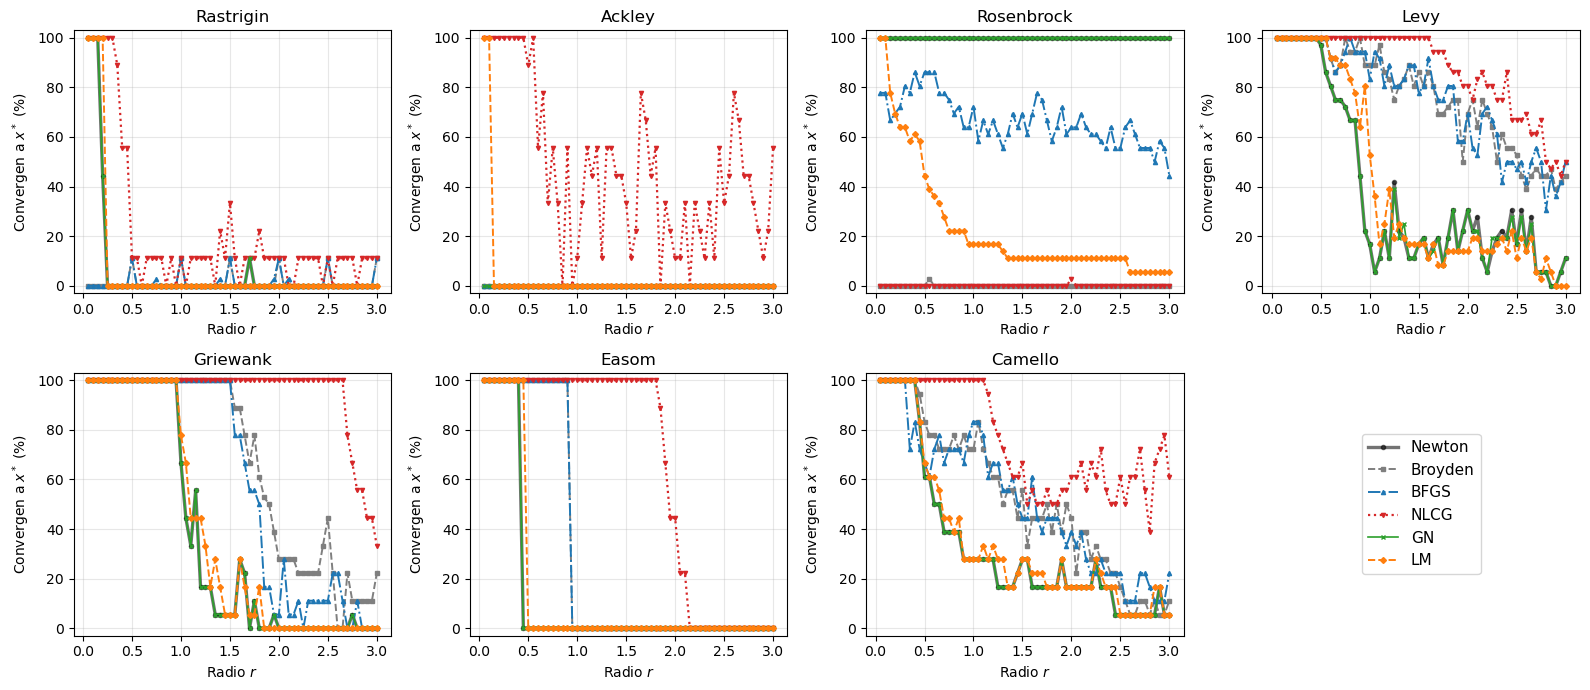

In [41]:
radios_fino = np.round(np.arange(0.05, 3.0001, 0.05), 2)
ESTILO = {'Newton':  dict(color='black',      marker='o', ls='-',  lw=2.4, alpha=0.55),
          'Broyden': dict(color='tab:gray',   marker='s', ls='--', lw=1.4),
          'BFGS':    dict(color='tab:blue',   marker='^', ls='-.', lw=1.4),
          'NLCG':    dict(color='tab:red',    marker='v', ls=':',  lw=1.6),
          'GN':      dict(color='tab:green',  marker='x', ls='-',  lw=1.2),
          'LM':      dict(color='tab:orange', marker='D', ls='--', lw=1.4)}

exito = {}
t0 = time.time()
for nombre in expr:
    xs = np.array(xmin[nombre])
    for metodo in METODOS:
        exito[(nombre, metodo)] = [100*sum(funciona(metodo, nombre, xs + r*np.array([np.cos(t), np.sin(t)]))
                                           for t in angulos)/len(angulos) for r in radios_fino]
    print(f"{nombre:<12} listo ({time.time()-t0:.0f} s)")

def grafica_exito(ax, nombre):
    for metodo in METODOS:
        ax.plot(radios_fino, exito[(nombre, metodo)], ms=3, label=metodo, **ESTILO[metodo])
    ax.set_title(nombre); ax.set_xlabel(r'Radio $r$'); ax.set_ylabel('Convergen a $x^*$ (%)')
    ax.set_ylim(-3, 103); ax.grid(alpha=0.3)

fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, nombre in zip(axs.flat, expr):
    grafica_exito(ax, nombre)
h, l = axs.flat[0].get_legend_handles_labels()
axs.flat[-1].axis('off'); axs.flat[-1].legend(h, l, loc='center', fontsize=11)
plt.tight_layout()
plt.savefig('figuras/t5_vecindad.pdf', bbox_inches='tight')
print('Guardada: figuras/t5_vecindad.pdf')
plt.show()

In [42]:
# Solo guarda cada figura por separado c:

for nombre in expr:
    fig, ax = plt.subplots(figsize=(5.2, 3.9))
    grafica_exito(ax, nombre)         # sin ax.legend()
    fig.tight_layout()
    fig.savefig(f'figuras/t5_vecindad_{nombre}.pdf', bbox_inches='tight')
    plt.close(fig)

from matplotlib.lines import Line2D

handles = [
    Line2D([0], [0], label=m,
           marker=ESTILO[m].get('marker', 'o'),
           markersize=5,
           color=ESTILO[m].get('color'),
           linestyle=ESTILO[m].get('linestyle', '-'))
    for m in METODOS
]

fig, ax = plt.subplots(figsize=(5.2, 3.9))
ax.axis('off')
ax.legend(handles=handles, loc='center', fontsize=11, ncol=1,
          title='Métodos', frameon=True)
fig.tight_layout()
fig.savefig('figuras/t5_vecindad_glosario.pdf', bbox_inches='tight')
plt.close(fig)

### Estancamiento de NLCG

NLCG elige el paso comparando valores de $F$ (condición de Armijo). Cuando $F(\mathbf{x}_k)-F(\mathbf{x}^*)$ es menor que el redondeo, la comparación ya no distingue un punto mejor de uno peor y la iteración deja de avanzar: el error se estanca en el orden de $10^{-9}$ a $10^{-8}$ y el método agota las 100 iteraciones aunque "acierte". Esto afecta la lectura de su velocidad (sección 5).

In [43]:
print(f"{'Función':<12}{'e final':>11}{'F(xk)-F(x*)':>14}{'‖∇F(xk)‖':>12}")
for nombre in expr:
    xs = np.array(xmin[nombre])
    xk, orb = corridas[(nombre, 'NLCG')]
    print(f"{nombre:<12}{np.linalg.norm(xk - xs):>11.2e}{F[nombre](xk) - F[nombre](xs):>14.2e}{np.linalg.norm(gradF[nombre](xk)):>12.1e}")

Función         e final   F(xk)-F(x*)    ‖∇F(xk)‖
Rastrigin      1.04e-09      0.00e+00     4.1e-07
Ackley         8.01e-13      2.27e-12     2.8e+00
Rosenbrock     1.33e-03      3.65e-07     4.9e-03
Levy           3.34e-09      7.08e-19     4.6e-10
Griewank       1.17e-08      0.00e+00     5.9e-09
Easom          1.88e-09      0.00e+00     5.6e-09
Camello        1.17e-11      1.65e-22     3.2e-11


## 5. Velocidad de convergencia

Con la órbita se calcula el error $e_k=\lVert\mathbf{x}_k-\mathbf{x}^*\rVert$ y el orden de convergencia estimado
$$
p_k=\frac{\ln(e_{k+1}/e_k)}{\ln(e_k/e_{k-1})}.
$$
Se usan solo los errores mayores que $10^{-13}$ para no medir ruido de redondeo, y solo las corridas que aciertan. Además se calculan los cocientes $e_{k+1}/e_k$: si la convergencia es lineal, tienden a una constante $\rho\in(0,1)$ (y $p\approx1$); si es superlineal, tienden a $0$.

Lo esperado es: $p\approx2$ (o $3$ si $F$ es par respecto a $\mathbf{x}^*$) en Newton y en GN, que coincide con él; superlineal en Broyden y BFGS; **lineal ($p\approx1$) en NLCG**; y en LM, $p\approx2$ cuando $\lambda$ se hace pequeño. Como la convergencia de los métodos de tipo Newton es muy rápida quedan pocos valores de $p_k$ por corrida, mientras que NLCG puede tener decenas; por eso en las tablas se muestran como máximo los últimos cuatro.

Dos medidas adicionales, útiles para comparar métodos de naturaleza distinta:

* $k_6$: la primera iteración con $e_k<10^{-6}$ (la misma cota con que se decide si el método *acierta*). A diferencia del número de puntos de la órbita, no depende del criterio de paro de cada código.
* $\bar\rho=(e_{k_6}/e_0)^{1/k_6}$: el factor promedio por iteración con que se reduce el error hasta $k_6$.

**NLCG se estanca** en un piso de error (sección 4), y a partir de ahí los cocientes valen $1$ o alternan (no son una tasa de convergencia). Para NLCG, $p_k$ y $e_{k+1}/e_k$ se calculan solo con el tramo hasta $k_6$.

In [44]:
def errores(nombre, orb):
    e = np.linalg.norm(orb - np.array(xmin[nombre]), axis=1)
    return e[e > 1e-13]          # descarta ruido de redondeo

def ordenes(e):
    """Lista de p_k para k = 1, ..., len(e)-2 (sin valores no finitos)."""
    with np.errstate(all='ignore'):
        p = [np.log(e[k+1]/e[k]) / np.log(e[k]/e[k-1]) for k in range(1, len(e)-1)]
    return [v for v in p if np.isfinite(v)]

def txt_pk(p):
    if not p:
        return 'n.d.'
    pre = '\\ldots,\\,' if len(p) > 4 else ''
    return '$' + pre + ',\\,'.join(f'{v:.2f}' for v in p[-4:]) + '$'

errs, pk, qk, k6, rho = {}, {}, {}, {}, {}
for nombre in expr:
    xs = np.array(xmin[nombre])
    for metodo in METODOS:
        res = corridas[(nombre, metodo)]
        if res is None:
            continue
        xk, orb = res
        e_full = np.linalg.norm(orb - xs, axis=1)
        errs[(nombre, metodo)] = e_full[e_full > 1e-13]          # para las gráficas
        if not acierta(nombre, xk):
            continue
        k = int(np.argmax(e_full < 1e-6))                          # primera iteración con e_k < 1e-6
        k6[(nombre, metodo)] = k
        rho[(nombre, metodo)] = (e_full[k]/e_full[0])**(1/k) if k > 0 else 0.0
        e = e_full[:k+1] if metodo == 'NLCG' else e_full           # NLCG: solo el tramo previo al estancamiento
        e = e[e > 1e-13]
        if len(e) < 2:
            continue
        pk[(nombre, metodo)] = ordenes(e)
        qk[(nombre, metodo)] = e[1:]/e[:-1]

for nombre in expr:
    print(nombre)
    for metodo in METODOS:
        if (nombre, metodo) not in k6:
            print(f"   {metodo:<8} no llega al mínimo global (no se estima p)" if corridas[(nombre, metodo)] is not None
                  else f"   {metodo:<8} falla")
            continue
        print(f"   {metodo:<8} k_6 = {k6[(nombre, metodo)]:>2}   rho_prom = {rho[(nombre, metodo)]:.3g}")
        if (nombre, metodo) not in pk:
            continue
        p, q = pk[(nombre, metodo)], qk[(nombre, metodo)]
        print(f"   {'':<8} errores usados: {len(p)+2:>3}   p_k = {np.array2string(np.round(p[-6:], 2), separator=', ')}"
              f"{'  (últimos 6)' if len(p) > 6 else ''}")
        print(f"   {'':<8} e_(k+1)/e_k = {np.array2string(q[-6:], precision=2, separator=', ')}{'  (últimos 6)' if len(q) > 6 else ''}")

Rastrigin
   Newton   k_6 =  3   rho_prom = 0.00025
            errores usados:   4   p_k = [3.09, 3.  ]
            e_(k+1)/e_k = [1.55e-01, 3.17e-03, 3.18e-08]
   Broyden  no llega al mínimo global (no se estima p)
   BFGS     no llega al mínimo global (no se estima p)
   NLCG     k_6 = 26   rho_prom = 0.619
            errores usados:  27   p_k = [1., 1., 1., 1., 1., 1.]  (últimos 6)
            e_(k+1)/e_k = [0.55, 0.55, 0.55, 0.55, 0.55, 0.55]  (últimos 6)
   GN       k_6 =  3   rho_prom = 0.00025
            errores usados:   4   p_k = [3.09, 3.  ]
            e_(k+1)/e_k = [1.55e-01, 3.17e-03, 3.18e-08]
   LM       k_6 =  3   rho_prom = 0.00025
            errores usados:   4   p_k = [3.09, 3.  ]
            e_(k+1)/e_k = [1.55e-01, 3.17e-03, 3.17e-08]
Ackley
   Newton   no llega al mínimo global (no se estima p)
   Broyden  no llega al mínimo global (no se estima p)
   BFGS     no llega al mínimo global (no se estima p)
   NLCG     k_6 = 11   rho_prom = 0.334
            errore

In [45]:
# Tablas
def ultimo_pk(nombre, metodo):
    if corridas[(nombre, metodo)] is None: return 'falla'
    if (nombre, metodo) not in k6: return '---'
    p = pk.get((nombre, metodo), [])
    return f"${p[-1]:.2f}$" if p else 'n.d.'

def ultimo_q(nombre, metodo):
    if corridas[(nombre, metodo)] is None: return 'falla'
    if (nombre, metodo) not in k6: return '---'
    if metodo == 'NLCG':                                  # NLCG: factor promedio, no el último cociente
        return f"$\\bar\\rho={rho[(nombre, metodo)]:.2f}$"
    q = qk.get((nombre, metodo))
    return '---' if q is None else sci(q[-1])

def txt_k6(nombre, metodo):
    if corridas[(nombre, metodo)] is None: return 'falla'
    return str(k6[(nombre, metodo)]) if (nombre, metodo) in k6 else '---'

guardar_tabla('t5_orden_p', ['Función'] + METODOS,
              [[f"\\texttt{{{n}}}"] + [ultimo_pk(n, m) for m in METODOS] for n in expr], 'l' + ' c'*len(METODOS))
guardar_tabla('t5_orden_q', ['Función'] + METODOS,
              [[f"\\texttt{{{n}}}"] + [ultimo_q(n, m) for m in METODOS] for n in expr], 'l' + ' c'*len(METODOS))
guardar_tabla('t5_k6', ['Función'] + METODOS,
              [[f"\\texttt{{{n}}}"] + [txt_k6(n, m) for m in METODOS] for n in expr], 'l' + ' c'*len(METODOS))
print('---: no llega a x*;  n.d.: llega, pero con menos de tres errores utilizables')

Guardada: tablas/t5_orden_p.tex
Guardada: tablas/t5_orden_q.tex
Guardada: tablas/t5_k6.tex
---: no llega a x*;  n.d.: llega, pero con menos de tres errores utilizables


### Error contra iteración

Una curva por método. En escala semilogarítmica, una convergencia lineal (NLCG) es una recta; la superlineal y la cuadrática se curvan hacia abajo.

Guardada: figuras/t5_convergencia.pdf


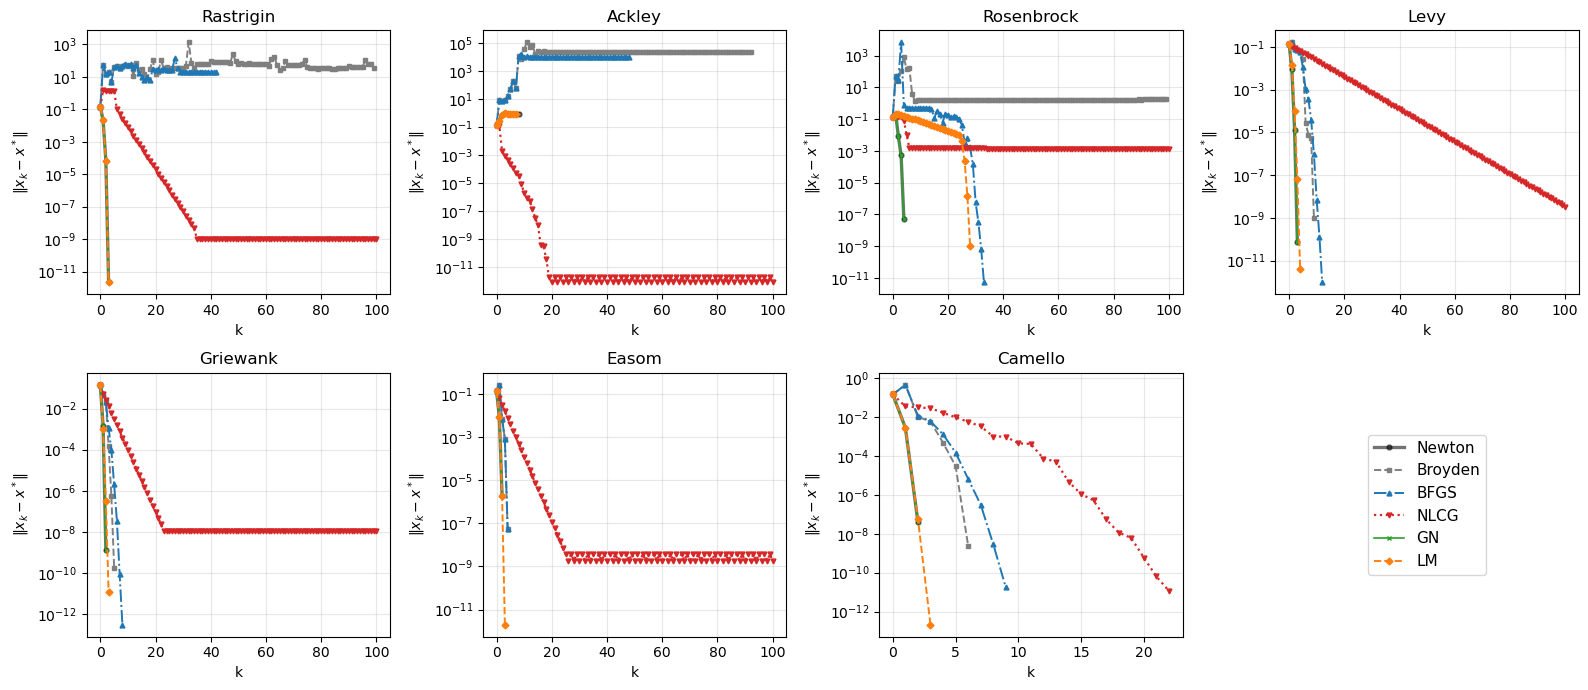

In [46]:
def grafica_conv(ax, nombre):
    for metodo in METODOS:
        if (nombre, metodo) in errs and len(errs[(nombre, metodo)]) > 0:
            ax.semilogy(errs[(nombre, metodo)], ms=3.5, label=metodo, **ESTILO[metodo])
    ax.set_title(nombre); ax.set_xlabel('k'); ax.set_ylabel(r'$\|x_k-x^*\|$'); ax.grid(alpha=0.3)

fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, nombre in zip(axs.flat, expr):
    grafica_conv(ax, nombre)
h, l = axs.flat[0].get_legend_handles_labels()
axs.flat[-1].axis('off'); axs.flat[-1].legend(h, l, loc='center', fontsize=11)
plt.tight_layout()
plt.savefig('figuras/t5_convergencia.pdf', bbox_inches='tight')
print('Guardada: figuras/t5_convergencia.pdf')
plt.show()


In [47]:
# Solo guarda cada figura por separado c:

for nombre in expr:
    fig, ax = plt.subplots(figsize=(5.2, 3.9))
    grafica_conv(ax, nombre)          # sin ax.legend()
    fig.tight_layout()
    fig.savefig(f'figuras/t5_conv_{nombre}.pdf', bbox_inches='tight')
    plt.close(fig)

from matplotlib.lines import Line2D

handles = [
    Line2D([0], [0], label=m,
           marker=ESTILO[m].get('marker', 'o'),
           markersize=5,
           color=ESTILO[m].get('color'),
           linestyle=ESTILO[m].get('linestyle', '-'))
    for m in METODOS
]

fig, ax = plt.subplots(figsize=(5.2, 3.9))
ax.axis('off')
ax.legend(handles=handles, loc='center', fontsize=11, ncol=1,
          title='Métodos', frameon=True)
fig.tight_layout()
fig.savefig('figuras/t5_conv_glosario.pdf', bbox_inches='tight')
plt.close(fig)

### Datos adicionales para el análisis

Para explicar por qué aciertan o fallan, se mide el **primer paso** de cada método desde $\mathbf{x}_0=\mathbf{x}^*+(0.1,0.1)$ en unidades de $\lVert\mathbf{h}\rVert=\lVert\mathbf{x}_0-\mathbf{x}^*\rVert=0.141$. Un paso razonable mide cerca de $1$. En LM el primer paso aceptado puede no ser el primero intentado (los rechazados no aparecen en la órbita).

Después, un resumen por método: en cuántas funciones acierta, mediana de puntos de la órbita y mediana de $k_6$ (ambas entre las corridas que aciertan) y mediana de $r_{\max}$ (con $\ge3$ contado como $3$).

In [48]:
hn = np.linalg.norm(np.array([0.1, 0.1]))
filas_pasos = []
print(f"{'Función':<12}" + ''.join(f"{m:>10}" for m in METODOS))
for nombre in expr:
    fila, fila_tex = [], [f"\\texttt{{{nombre}}}"]
    for metodo in METODOS:
        res = corridas[(nombre, metodo)]
        if res is None or len(res[1]) < 2:
            fila.append('falla'); fila_tex.append('falla'); continue
        s0 = np.linalg.norm(res[1][1] - res[1][0]) / hn
        fila.append(f"{s0:.3g}"); fila_tex.append(f"${s0:.3g}$")
    print(f"{nombre:<12}" + ''.join(f"{v:>10}" for v in fila))
    filas_pasos.append(fila_tex)
guardar_tabla('t5_pasos', [r'Función'] + METODOS, filas_pasos, 'l' + ' r'*len(METODOS))

USA = {'Newton': r'$\nabla F,\ \nabla^2F$', 'Broyden': r'$\nabla F$', 'BFGS': r'$\nabla F$',
       'NLCG': r'$F,\ \nabla F$', 'GN': r'$\nabla F,\ \nabla^2F$', 'LM': r'$\nabla F,\ \nabla^2F$'}
filas_res = []
print(f"\n{'Método':<9}{'Aciertos':>9}{'Iter. mediana':>15}{'k_6 mediano':>13}{'r_max mediano':>15}")
for metodo in METODOS:
    ok = [n for n in expr if corridas[(n, metodo)] is not None and acierta(n, corridas[(n, metodo)][0])]
    it_med = np.median([len(corridas[(n, metodo)][1]) for n in ok]) if ok else float('nan')
    r_med = np.median([rmax[(n, metodo)] for n in expr])
    k6_med = np.median([k6[(n, metodo)] for n in ok]) if ok else float('nan')
    print(f"{metodo:<9}{len(ok):>7}/7{it_med:>15.1f}{k6_med:>13.1f}{r_med:>15.2f}")
    filas_res.append([metodo, USA[metodo], f"{len(ok)}/7", '---' if not ok else f"{it_med:.1f}",
                      '---' if not ok else f"{k6_med:.1f}", f"${r_med:.2f}$"])
guardar_tabla('t5_resumen', ['Método', 'Usa', 'Aciertos', 'Iter. mediana', r'$k_6$ mediano', r'$r_{\max}$ mediano'],
              filas_res, 'l l c r r r')

Función         Newton   Broyden      BFGS      NLCG        GN        LM
Rastrigin         1.16       371       371      11.6      1.16      1.16
Ackley            3.03      61.1      61.1      1.91      3.03      3.03
Rosenbrock       0.711       377       377     0.368     0.711     0.711
Levy             0.936      1.68      1.68     0.838     0.936     0.916
Griewank          1.01     0.787     0.787     0.787      1.01      1.01
Easom             1.06      2.91      2.91      1.46      1.06      1.06
Camello           1.01       4.1       4.1      1.02      1.01      1.01
Guardada: tablas/t5_pasos.tex

Método    Aciertos  Iter. mediana  k_6 mediano  r_max mediano
Newton         6/7            6.0          3.0           0.42
Broyden        4/7            8.5          5.0           0.44
BFGS           5/7           11.0          7.0           0.28
NLCG           6/7          101.0         17.0           1.14
GN             6/7            4.5          3.0           0.42
LM           

## 6. Conclusiones

**Mínimos.** Desde $\mathbf{x}^*+(0.1,0.1)$, con $\mathrm{tol}=10^{-10}$ y a lo más 100 iteraciones, aciertan: Newton 6/7, Broyden 4/7, BFGS 5/7, NLCG 6/7, GN 6/7 y LM 6/7.

* **GN, LM y Newton** fallan solo en Ackley, donde terminan en el máximo local $(-0.673,-0.673)$: el mínimo está en un pico cónico donde la Hessiana no existe.
* **BFGS** acierta en Rosenbrock (35 puntos de órbita), donde Broyden no, pero falla en Rastrigin y Ackley igual que Broyden. Con $B_0=I$ el primer paso mide $371$ (Rastrigin) y $61$ (Ackley) veces la distancia al mínimo (Broyden y BFGS dan el mismo primer paso), frente a $0.8$ a $4.1$ en las funciones donde aciertan.
* **NLCG** llega al mínimo en Ackley (el único método que lo logra, porque decide con los valores de $F$ y no con el gradiente) y falla en Rosenbrock: termina en $(0.9994,0.9988)$, con $\lVert\nabla F\rVert=4.9\times10^{-3}$, sin agotar el valle en 100 iteraciones.
* En las corridas que no aciertan, BFGS termina lejos de $\mathbf{x}^*$ (en un punto crítico que no es el mínimo global en Rastrigin, y en una zona casi plana lejana en Ackley); Newton, GN y LM, en un máximo local.

**Vecindad.** Radio $r_{\max}$ (todas las direcciones, a lo más 100 iteraciones, tope $3$):

| Función | Newton | Broyden | BFGS | NLCG | GN | LM | $r_H$ |
|---|---|---|---|---|---|---|---|
| Rastrigin | 0.18 | 0 | 0 | 0.08 | 0.18 | 0.20 | 0.26 |
| Ackley | 0 | 0 | 0 | 0.48 | 0 | 0.12 | 0.19 |
| Rosenbrock | $\ge3$ | 0 | 0 | 0 | $\ge3$ | 0.11 | 0.01 |
| Levy | 0.49 | 0.58 | 0.58 | 1.58 | 0.49 | 0.57 | 0.77 |
| Griewank | 0.95 | 1.53 | 1.50 | 2.68 | 0.95 | 0.97 | 1.29 |
| Easom | 0.41 | 0.93 | 0.93 | 1.83 | 0.41 | 0.45 | 0.59 |
| Camello | 0.42 | 0.44 | 0.28 | 1.14 | 0.42 | 0.43 | 0.57 |

* **GN** tiene exactamente la misma vecindad que Newton, como se esperaba ($r=\nabla F$, $J=\nabla^2F$).
* **LM** la amplía poco (Rastrigin, Levy, Griewank, Easom) y es la única de los tres que tiene vecindad en Ackley ($0.12$), pero es más pequeña en Rosenbrock ($0.11$ frente a $\ge3$).
* **BFGS y Broyden** tienen vecindades parecidas, con $r_{\max}=0$ donde el primer paso es enorme. En Levy, Griewank y Easom son mayores que las de Newton.
* **NLCG** tiene la vecindad más grande en cinco de las siete funciones (Levy, Griewank, Easom, Camello y Ackley). Como los demás, está limitada por el máximo de 100 iteraciones, y su región de éxito no es una bola: en Rastrigin $r_{\max}=0.08$, pero acierta en las 36 direcciones con $r=0.1$ y $r=0.25$.

**Velocidad.** Con $p_k$ y los cocientes $e_{k+1}/e_k$ (y $k_6$, las iteraciones para llegar a $e_k<10^{-6}$):

* **GN** reproduce a Newton: mismos $p_k$ ($\approx3$ en Rastrigin, Griewank, Easom y Camello, que son pares respecto a $\mathbf{x}^*$ y diferenciables en él; $2.45$ y $1.82$ en Levy; no concluyente en Rosenbrock) y mismo $k_6$ (2 a 4).
* **LM** tiene el mismo $k_6$ que Newton salvo en Rosenbrock ($28$ frente a $4$). Sus $p_k$ son más bajos que los de Newton en las últimas iteraciones (entre $1.2$ y $1.6$ en Levy, Griewank, Easom y Camello), pero los cocientes terminan en $10^{-5}$ a $10^{-6}$: convergencia superlineal, y con muy pocos datos para asignar un orden.
* **BFGS y Broyden** son superlineales: los cocientes bajan hasta $10^{-2}$ a $10^{-5}$ y los $p_k$ son erráticos (entre $-5.6$ y $25$), por lo que no se asigna un orden. Broyden termina con cocientes menores ($\sim10^{-4}$ frente a $\sim10^{-3}$ a $10^{-2}$ de BFGS, salvo Easom, donde ambos coinciden) y con menor $k_6$ mediano ($5$ frente a $7$).
* **NLCG** es lineal: $p_k\approx1$ y cociente constante en Rastrigin, Levy, Griewank y Easom, con $\bar\rho=0.62$, $0.84$, $0.49$ y $0.50$ y $k_6=26$, $68$, $17$ y $17$. En Ackley y Camello los cocientes son irregulares. Además se estanca en un error de $10^{-9}$ a $10^{-8}$ porque $F(\mathbf{x}_k)-F(\mathbf{x}^*)$ queda por debajo del redondeo (sección 4), por lo que casi siempre agota las 100 iteraciones.

**Comparación con Newton y Broyden.**

| Método | Aciertos | $k_6$ mediano | $r_{\max}$ mediano | Usa |
|---|---|---|---|---|
| Newton | 6/7 | 3 | 0.42 | $\nabla F,\nabla^2F$ |
| Broyden | 4/7 | 5 | 0.44 | $\nabla F$ |
| BFGS | 5/7 | 7 | 0.28 | $\nabla F$ |
| NLCG | 6/7 | 17 | 1.14 | $F,\nabla F$ |
| GN | 6/7 | 3 | 0.42 | $\nabla F,\nabla^2F$ |
| LM | 6/7 | 3 | 0.43 | $\nabla F,\nabla^2F$ |

* **GN y LM** igualan a Newton en aciertos y velocidad, sin mejorarlo de forma apreciable. GN es Newton con otro criterio de paro, y LM solo agrega robustez en Ackley y algo de radio, a costa de ser más lento en Rosenbrock.
* **BFGS** mejora a Broyden en aciertos (5 frente a 4), pero tiene el mismo problema con $B_0=I$ y un $r_{\max}$ mediano menor.
* **NLCG** es el más tolerante al punto inicial y el único que usa $F$, pero es el más lento (lineal, $k_6$ mediano $17$ contra $3$ de Newton) y no alcanza la precisión de los demás.
* Ninguno es global: todos dependen de partir cerca de $\mathbf{x}^*$, y los que resuelven $\nabla F=0$ (todos salvo NLCG) pueden terminar en máximos o puntos silla.
